# <b>ETH.</b>

# <b>Problem Statement.</b>

We solve the problem of building a toxic trade filter. For each trade, we observe market features $X_i$, trade weight $w_i$, and the realized maker PnL over a selected horizon $t$, for example $30s$:

The model's task is to predict the expected PnL from the trade features:
$\hat y_i = f(X_i).$

On the calibration set, we tune the threshold. For each possible threshold value, we construct a binary filter:

$
a_i =
\begin{cases}
1, & toxicity_i > threshold, \\
0, & toxicity_i \le threshold.
\end{cases}
$

The threshold is selected **only on the calibration set**. The objective is to maximize the Score under a constraint on the minimum remaining turnover:
$Score = PnL_{kept} - PnL_{all}.$


## <b>Schematic.</b>

```text
Features X
   ↓
Regression model on train
   ↓
Predicted PnL
   ↓
Toxicity = - Predicted PnL
   ↓
Threshold tuning on calib
   ↓
Embargo
   ↓
Final OOS test evaluation



## <b>Imports.</b>

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))

from experiment import (
    WalkForwardConfig,
    walk_forward
)
from features import get_feature_set
from splits import get_window_ids

import utilities as util

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"X does not have valid feature names, but LGBMRegressor was fitted with feature names",
    category=UserWarning
)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")

## <b>0. Config.</b>

In [ ]:
INSTRUMENT = "eth"                    # "btc" or "eth"
MODEL_NAME = "lgbm_huber"
HORIZONS   = [30, 120, 300]

MAX_FILTER_RATES = [0.99, 0.995, 0.999]
FOCUS_FILTER_RATE = 0.999             # used for per-trade histograms

SPLIT_DIR = Path(f"data/meta/{INSTRUMENT}_splits_only")

BASE_FEATURES = get_feature_set("advanced", horizons_s=HORIZONS)
print(f"Base features ({len(BASE_FEATURES)}): {BASE_FEATURES}")

Base features (40): ['spread', 'obi', 'dist_to_mid', 'hour', 'vpin_5s', 'vpin_30s', 'vpin_120s', 'rv_5s', 'rv_30s', 'rv_120s', 'liq_binance_5s', 'liq_binance_30s', 'liq_binance_120s', 'liq_bybit_5s', 'liq_bybit_30s', 'liq_bybit_120s', 'log_notional', 'net_liq_5s', 'net_liq_30s', 'net_liq_120s', 'liq_agreement_30s', 'signed_dist_to_mid', 'signed_obi', 'signed_liq_binance_5s', 'signed_liq_binance_30s', 'signed_liq_binance_120s', 'signed_liq_bybit_5s', 'signed_liq_bybit_30s', 'signed_liq_bybit_120s', 'vpin_ratio_5_120', 'rv_ratio_5_120', 'liq_binance_ratio_5_120', 'liq_bybit_ratio_5_120', 'dist_to_mid_over_spread', 'notional_over_median', 'liq_aligned_5s', 'liq_aligned_30s', 'liq_aligned_120s', 'liq_direction_agreement_30s', 'liq_accel_5_30']


## <b>1. Walk-Forward.</b>

| window | train | embargo | test |
|---|---|---|---|
| W1 | 2025-11-01 .. 11-30 | 12-01 .. 12-07 | 2025-12-08 .. 12-31 |
| W2 | 2025-11-01 .. 12-31 | 01-01 .. 01-07 | 2026-01-08 .. 01-31 |
| W3 | 2025-11-01 .. 01-31 | 02-01 .. 02-07 | 2026-02-08 .. 02-28 |
| W4 | 2025-11-01 .. 02-28 | 03-01 .. 03-07 | 2026-03-08 .. 03-31 |
| W5 | 2025-11-01 .. 03-31 | 04-01 .. 04-07 | 2026-04-08 .. 04-28 |

Walk-forward validation is used to check the quality of the filter. Each window consists of three parts:

1. `train_model` - the subset of data used to train the PnL model;
2. `calib` - the portion of the data used to determine the toxicity threshold;
3. `test` - the fully validated out-of-sample portion, on which the final metrics are calculated.


In [ ]:
# Dictionary of WalkForwardResult objects.
results: dict[tuple[str, int], object] = {}

for tau in HORIZONS:

    config = WalkForwardConfig(
            instrument       = INSTRUMENT,
            tau              = tau,
            model_name       = MODEL_NAME,
            max_filter_rates = MAX_FILTER_RATES,
            window_ids       = get_window_ids(),
            verbose          = False,
            use_tqdm         = True
        )

    results[("base", tau)] = walk_forward(
            config     = config,
            features   = BASE_FEATURES,
            split_dir  = SPLIT_DIR
        )

WF eth lgbm_huber tau=30s:   0%|          | 0/5 [00:00<?, ?it/s]

WF eth lgbm_huber tau=120s:   0%|          | 0/5 [00:00<?, ?it/s]

WF eth lgbm_huber tau=300s:   0%|          | 0/5 [00:00<?, ?it/s]

## <b>2. Summary table.</b>

In [ ]:
summary_table = util.build_wf_summary_table(
    results         = results,
    max_filter_rate = FOCUS_FILTER_RATE
)

summary_table

,variant,tau,window,max_filter_rate,pnl_all,pnl_kept,pnl_filtered,score,"kept_turnover_per_day, mln$",turnover_ok,filter_rate
0,base,30,W1,0.999,-0.017476,10.526957,-0.154298,10.544433,3.35,True,0.9938
1,base,30,W2,0.999,-0.098579,9.347041,-0.244880,9.445620,4.20,True,0.9931
2,base,30,W3,0.999,-0.109866,12.956435,-0.221758,13.066301,2.00,True,0.9965
3,base,30,W4,0.999,-0.123401,2.399393,-0.149994,2.522794,2.64,True,0.9952
4,base,30,W5,0.999,-0.110326,0.271494,-0.480056,0.381820,103.81,True,0.5699
5,base,120,W1,0.999,0.168486,8.091085,0.041326,7.922600,4.14,True,0.9910
6,base,120,W2,0.999,0.124330,28.866050,-0.554610,28.741719,6.35,True,0.9874
7,base,120,W3,0.999,-0.006987,19.036035,-0.092872,19.043021,1.06,True,0.9983
8,base,120,W4,0.999,-0.249273,23.984527,-0.452744,24.233800,2.11,True,0.9959
9,base,120,W5,0.999,-0.018461,6.971924,-0.052076,6.990386,1.01,True,0.9971


## <b>3. Chart with scores.</b>

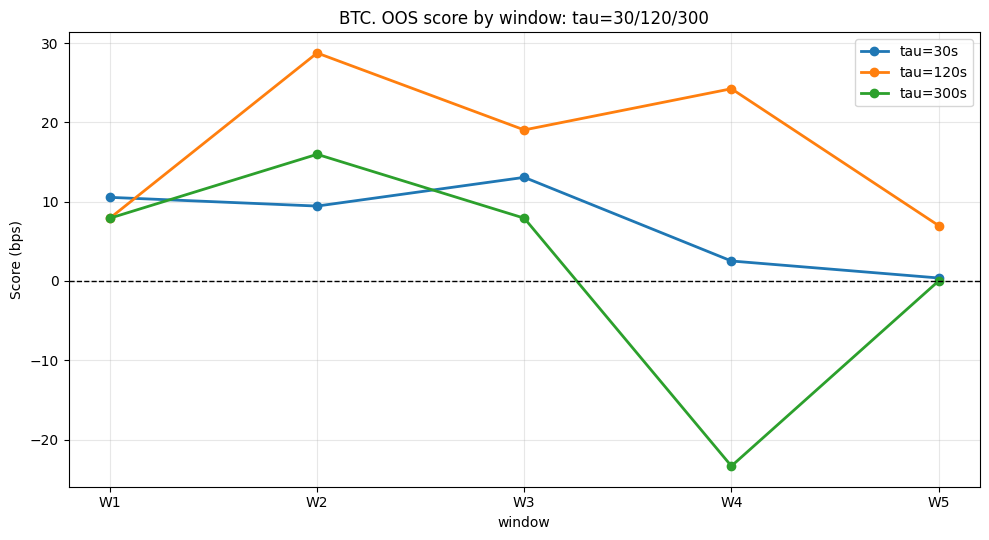

tau,30,120,300
window,,,
W1,10.544433,7.922600,7.919318
W2,9.445620,28.741719,15.969817
W3,13.066301,19.043021,7.917317
W4,2.522794,24.233800,-23.328883
W5,0.381820,6.990386,0.000000


In [ ]:
pivot_scores = util.plot_score_by_window_one_chart(
    summary_table       = summary_table,
    variant             = "base",
    taus                = (30, 120, 300),
    title               = "ETH. OOS score by window: tau=30/120/300"
)

pivot_scores

## <b>4. Distributions charts.</b>


ETH_lgbm_huber_base_tau120s_fr0.999
Daily Score:
  mean   = +13.956550
  std    = 22.651712
  median = +12.005392
  min    = -78.427618
  max    = +71.683281
  >0 days: 86/106 (81%)
  <0 days: 20/106 (19%)

ETH_lgbm_huber_base_tau120s_fr0.999
Daily PnL kept:
  mean   = +13.945116
  std    = 22.797060
  median = +12.046539
  min    = -79.848910
  max    = +67.939866
  >0 days: 85/106 (80%)
  <0 days: 21/106 (20%)



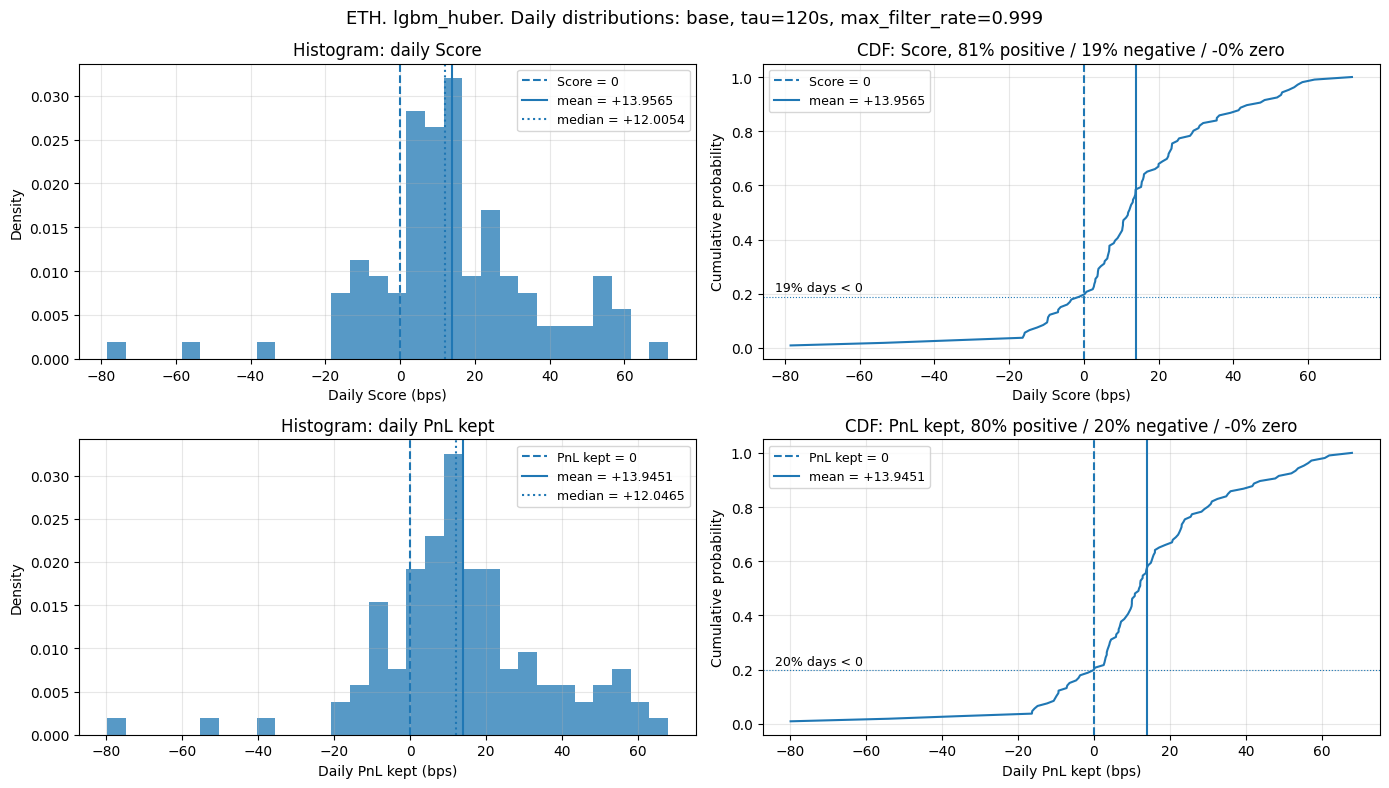

c:\Users\Klimn\Desktop\Experiment Pipeline\utilities.py:378: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Klimn\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


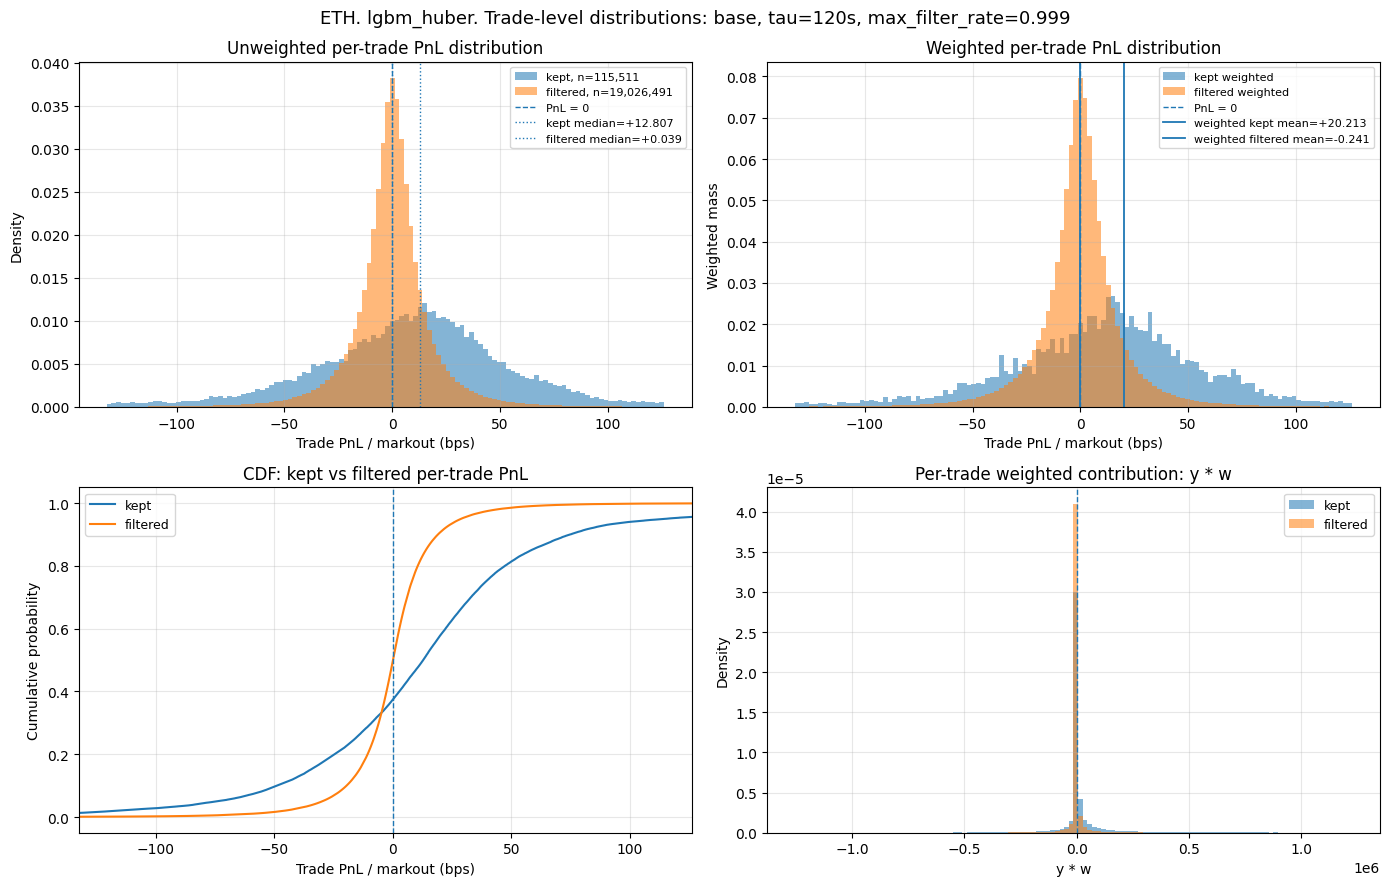

ETH | lgbm_huber | base | tau=120s | max_filter_rate=0.999
--------------------------------------------------------------------------------
n_all      = 19,142,002
n_kept     = 115,511 (0.60%)
n_filtered = 19,026,491 (99.40%)

Weighted PnL:
  pnl_all      = +0.008791 bps
  pnl_kept     = +20.212708 bps
  pnl_filtered = -0.240660 bps
  score        = +20.203917 bps

Unweighted per-trade PnL:
  all      mean=-0.129338, median=+0.057214, <0=49.8%
  kept     mean=+16.868929, median=+12.806890, <0=37.4%
  filtered mean=-0.232535, median=+0.038597, <0=49.8%


In [ ]:
daily = util.plot_daily_score_distribution(
    results         = results,
    variant         = "base",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)

trade = util.plot_per_trade_distribution(
    results         = results,
    variant         = "base",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)


## <b>5. Feature importance.</b>

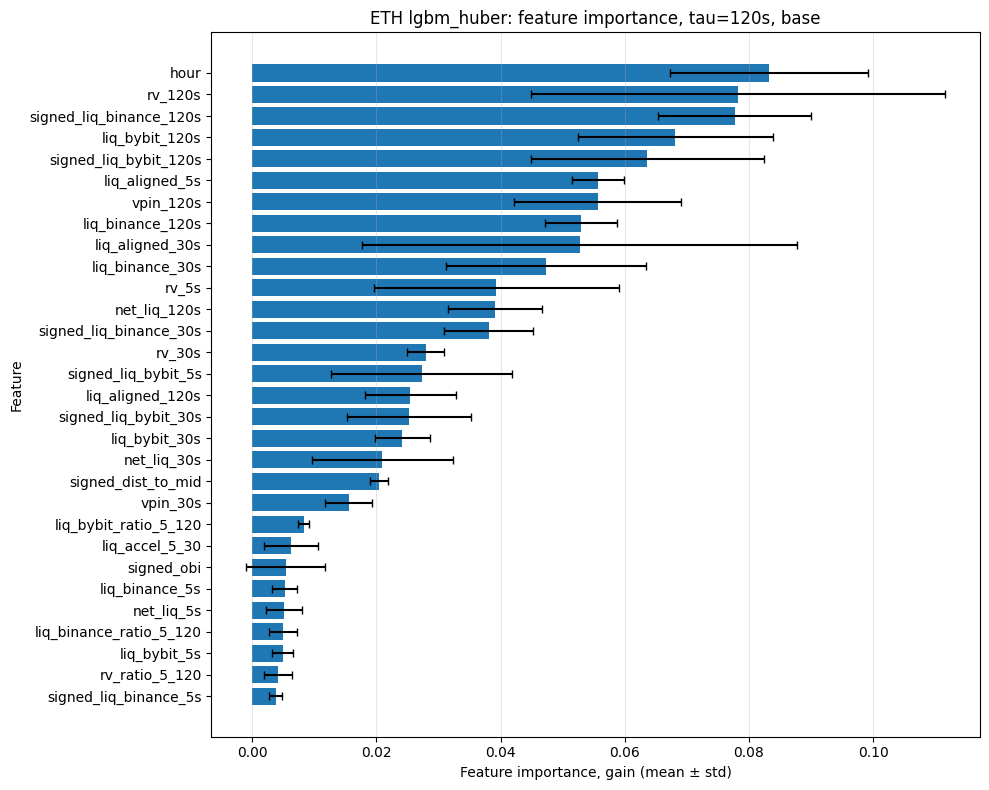

,feature,mean_importance,std_importance,n_models,sem_importance,interval
2,hour,0.083206,0.015931,5,0.007125,0.015931
23,rv_120s,0.078256,0.033324,5,0.014903,0.033324
28,signed_liq_binance_120s,0.077737,0.012322,5,0.005510,0.012322
12,liq_bybit_120s,0.068132,0.015663,5,0.007005,0.015663
31,signed_liq_bybit_120s,0.063662,0.018774,5,0.008396,0.018774
7,liq_aligned_5s,0.055691,0.004209,5,0.001882,0.004209
36,vpin_120s,0.055621,0.013416,5,0.006000,0.013416
8,liq_binance_120s,0.053004,0.005770,5,0.002580,0.005770
6,liq_aligned_30s,0.052736,0.035060,5,0.015679,0.035060
9,liq_binance_30s,0.047347,0.016089,5,0.007195,0.016089


In [ ]:
tau = 120
variant = "base"

result = results[("base", tau)]

fi = util.plot_lgbm_feature_importance(
    models              = result.models,
    top_n              = 30,
    importance_type    = "gain",
    interval           = "std",
    normalize_per_model= True,
    figsize            = (10, 8),
    title              = f"{INSTRUMENT.upper()} {MODEL_NAME}: feature importance, tau={tau}s, {variant}"
)

display(fi.head(30))

---
## <b>Executive summary</b>

On ETH, the best result was obtained for the time horizon $$\tau = 120s.$$

For the `lgbm_huber` model with `max_filter_rate = 0.999`, this horizon yields a positive out-of-sample score in all walk-forward windows:

$$
W1: +7.92,\quad
W2: +28.75,\quad
W3: +19.04,\quad
W4: +24.23,\quad
W5: +6.99\ \text{bps}.
$$

The average score across the five windows is approximately $$+17.4\ \text{bps}.$$

This is the best and most consistent result among the three time horizons. The turnover constraint is satisfied in all windows, so the result is valid in terms of kept turnover.

The `30s` time horizon also yields a positive result in all windows:

$$
W1: +10.54,\quad
W2: +9.45,\quad
W3: +13.06,\quad
W4: +2.52,\quad
W5: +0.38\ \text{bps}.
$$

The average score for `30s` is approximately

$$
+7.2\ \text{bps}.
$$

This result is stable, but noticeably weaker than at the `120s` time scale.

The `300s` time scale proved to be unstable. Despite positive values in the first three windows,

$$
W1: +7.92,\quad
W2: +15.97,\quad
W3: +7.92\ \text{bps},
$$

A strong negative result appears in window `W4`:

$$
W4: -23.33\ \text{bps},
$$

and in `W5`, the model falls back to the no-filter state:

$$
W5: 0.00\ \text{bps}.
$$

For this reason, `300s` is not considered the primary trading horizon.

The main conclusion regarding ETH: the strongest and most stable configuration is `lgbm_huber` on the `120s` horizon. It yields an average score of about

$$
+17.4\ \text{bps}
$$

and a positive result in all walk-forward windows. The `30s` horizon can be considered an additional stable signal, while the `300s` horizon requires caution due to significant instability across the windows.